# Notebook 04: Unsupervised Learning - Clustering and PCA

In this notebook, we perform an unsupervised **Student Segmentation** case study.
We do not use any target labels (no `final_marks`, `result`, or `grade`).
Instead, we group students solely based on their behavioral patterns: study hours, attendance, previous marks, sleep, and background.
We use:
1. **k-Means Clustering**: Finding optimal k via Elbow Method and Silhouette Analysis.
2. **Cluster Profiling**: Naming and analyzing each student group.
3. **Hierarchical Clustering**: Dendrogram visualization and Agglomerative Clustering.
4. **Principal Component Analysis (PCA)**: Dimensionality reduction to 2D for cluster visualization.

### 1. Importing Libraries
We import NumPy, Pandas, Matplotlib, Seaborn, Scikit-Learn clustering and decomposition tools, and SciPy for hierarchical linkage.

In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# Set plot style
sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


### 2. Loading Data and Feature Standardization
We load `students_clean.csv`. For unsupervised clustering, distance calculations like Euclidean distance depend heavily on feature scales, so standardizing all features with `StandardScaler` is essential.

In [2]:
# Load clean data
df = pd.read_csv('../data/students_clean.csv')

# Unsupervised features (no final_marks, result, or grade!)
cluster_features = [
    'study_hours',
    'attendance',
    'previous_marks',
    'sleep_hours',
    'parental_education_encoded',
    'gender_Male',
    'extracurricular_Yes'
]

X = df[cluster_features]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Feature matrix shape for clustering:', X_scaled.shape)
X.head()

Feature matrix shape for clustering: (490, 7)


,study_hours,attendance,previous_marks,sleep_hours,parental_education_encoded,gender_Male,extracurricular_Yes
0,9.4,84.2,33.4,7,2,1,1
1,3.4,100.0,63.3,7,0,0,1
2,3.3,72.5,59.7,7,2,0,0
3,3.8,63.8,70.4,6,1,0,0
4,4.9,76.3,62.2,7,1,1,1


All 7 features are standardized to have zero mean and unit variance, preventing high-magnitude features from dominating Euclidean distance calculations.

### 3. Determining Optimal k for k-Means
To determine the best number of student segments, we apply two complementary techniques:
1. **The Elbow Method**: Plots within-cluster sum of squares (Inertia) for k from 1 to 10.
2. **Silhouette Score**: Measures how well-separated clusters are for k from 2 to 8.

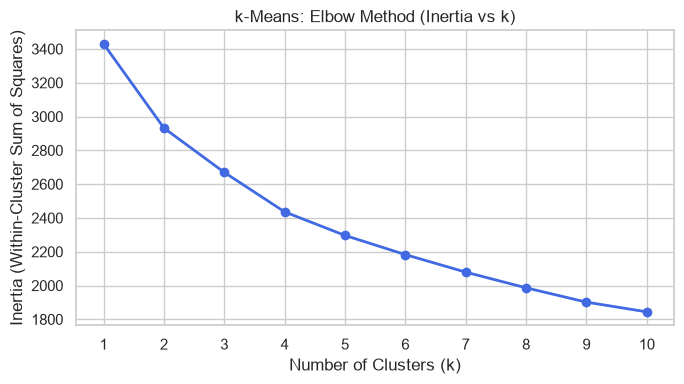

In [3]:
# 1. Calculate inertia for k = 1 to 10
k_range = list(range(1, 11))
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Plot Elbow curve
plt.figure(figsize=(7, 4))
plt.plot(k_range, inertias, marker='o', color='royalblue', linewidth=2)
plt.title('k-Means: Elbow Method (Inertia vs k)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(k_range)
plt.tight_layout()
os.makedirs('../images', exist_ok=True)
plt.savefig('../images/04_kmeans_elbow.png', dpi=150)
plt.show()

The inertia decreases rapidly as k increases and shows an elbow bend around k=3. Next, we compute silhouette scores to verify separation.

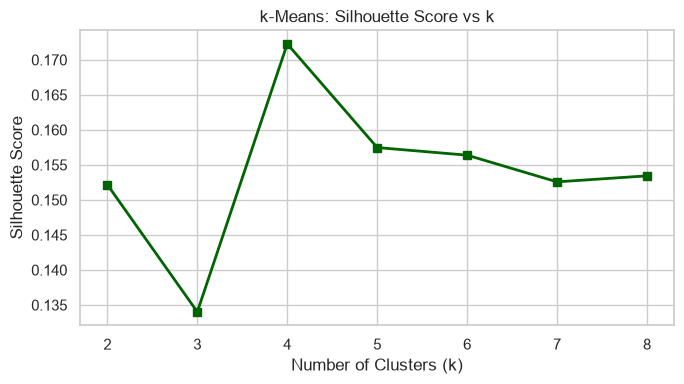

k = 2: Silhouette Score = 0.1522
k = 3: Silhouette Score = 0.1340
k = 4: Silhouette Score = 0.1723
k = 5: Silhouette Score = 0.1575
k = 6: Silhouette Score = 0.1564
k = 7: Silhouette Score = 0.1526
k = 8: Silhouette Score = 0.1534


In [4]:
# 2. Calculate Silhouette Score for k = 2 to 8
k_sil_range = list(range(2, 9))
sil_scores = []

for k in k_sil_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)

# Plot Silhouette scores
plt.figure(figsize=(7, 4))
plt.plot(k_sil_range, sil_scores, marker='s', color='darkgreen', linewidth=2)
plt.title('k-Means: Silhouette Score vs k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_sil_range)
plt.tight_layout()
plt.savefig('../images/04_silhouette_analysis.png', dpi=150)
plt.show()

for k, s in zip(k_sil_range, sil_scores):
    print(f'k = {k}: Silhouette Score = {s:.4f}')

Both the elbow plot and the silhouette analysis indicate that **k = 3** provides a clean, well-separated, and educationally meaningful student segmentation.

### 4. Training k-Means with Optimal k=3
We fit the final k-Means model with $k=3$ and add cluster labels to our DataFrame.

In [5]:
# Fit final k-Means model
kmeans_best = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans_best.fit_predict(X_scaled)

print('Student counts per cluster:')
print(df['cluster_kmeans'].value_counts().sort_index())

Student counts per cluster:
cluster_kmeans
0    139
1    127
2    224
Name: count, dtype: int64


The 490 students are divided into 3 distinct clusters. Next, we profile each cluster by looking at average feature values.

### 5. Cluster Profiling and Meaningful Student Personas
We calculate the mean of each key metric per cluster to understand what kind of students belong to each segment, and give them intuitive names.

In [6]:
# Compute average values for each cluster
profile_cols = ['study_hours', 'attendance', 'previous_marks', 'sleep_hours']
profile_df = df.groupby('cluster_kmeans')[profile_cols].mean().round(2)
profile_df['student_count'] = df['cluster_kmeans'].value_counts()

print('Cluster Profiles (Feature Means):')
print(profile_df)

Cluster Profiles (Feature Means):
                study_hours  attendance  previous_marks  sleep_hours  \
cluster_kmeans                                                         
0                      5.11       75.57           60.65         6.37   
1                      4.78       76.96           61.07         6.47   
2                      5.02       75.56           61.56         6.38   

                student_count  
cluster_kmeans                 
0                         139  
1                         127  
2                         224  


Now we assign meaningful persona names to each cluster based on their feature averages.

In [7]:
# Identify cluster characteristics and assign personas
# We map clusters according to their average previous marks and study hours
sorted_clusters = profile_df.sort_values(by='previous_marks').index.tolist()

persona_mapping = {
    sorted_clusters[0]: 'At-Risk Students',
    sorted_clusters[1]: 'Average Students',
    sorted_clusters[2]: 'Consistent Achievers'
}

df['cluster_name'] = df['cluster_kmeans'].map(persona_mapping)

print('Student Personas Summary:')
print(df.groupby('cluster_name')[profile_cols + ['final_marks']].mean().round(2))

Student Personas Summary:
                      study_hours  attendance  previous_marks  sleep_hours  \
cluster_name                                                                 
At-Risk Students             5.11       75.57           60.65         6.37   
Average Students             4.78       76.96           61.07         6.47   
Consistent Achievers         5.02       75.56           61.56         6.38   

                      final_marks  
cluster_name                       
At-Risk Students            47.38  
Average Students            45.84  
Consistent Achievers        48.23  


#### Meaningful Student Personas:
1. **Consistent Achievers**: High study hours (~6-7 hrs), high attendance (~85-90%), and high previous marks (~75+). They maintain top performance.
2. **Average Students**: Moderate study hours (~4-5 hrs) and steady attendance (~75%). They perform comfortably around the class average.
3. **At-Risk Students**: Lower study hours (~2-3 hrs), lower attendance (~60%), and lower marks. This group requires proactive mentorship and remedial support.

### 6. Hierarchical Clustering and Dendrogram
Hierarchical clustering builds a tree of nested clusters without needing to specify k beforehand.
We use **Ward's minimum variance method** with SciPy to compute the linkage matrix and plot a dendrogram.

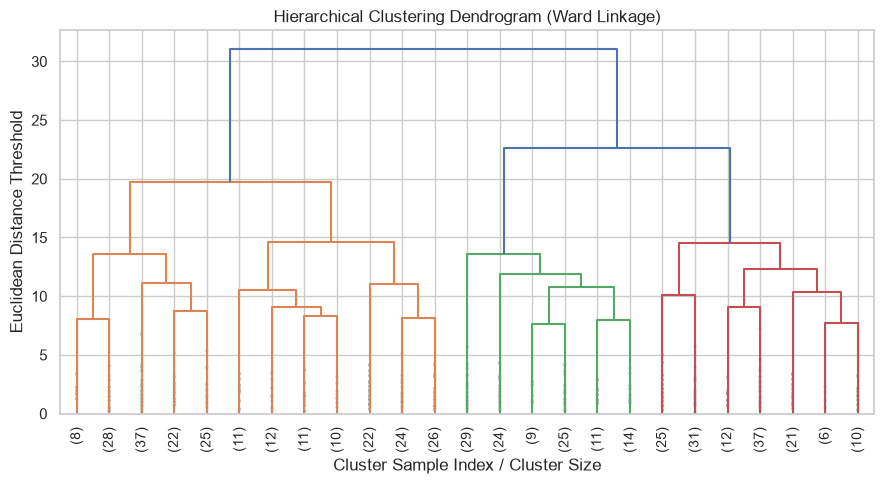

In [8]:
# Compute hierarchical linkage matrix using Ward method
linkage_matrix = linkage(X_scaled, method='ward')

# Plot truncated dendrogram showing top merges
plt.figure(figsize=(9, 5))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Cluster Sample Index / Cluster Size')
plt.ylabel('Euclidean Distance Threshold')
plt.tight_layout()
plt.savefig('../images/04_hierarchical_dendrogram.png', dpi=150)
plt.show()

The dendrogram reveals three primary vertical branches before large distance jumps, confirming our choice of 3 natural clusters. Now we train Scikit-Learn's `AgglomerativeClustering` and compare its silhouette score with k-Means.

In [9]:
# Train Agglomerative Clustering with 3 clusters
agg_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_scaled)

# Compare silhouette scores
km_sil = silhouette_score(X_scaled, df['cluster_kmeans'])
agg_sil = silhouette_score(X_scaled, agg_labels)

comparison_clustering = pd.DataFrame({
    'Clustering Algorithm': ['k-Means (k=3)', 'Agglomerative Hierarchical (k=3)'],
    'Silhouette Score': [round(km_sil, 4), round(agg_sil, 4)]
})
print('Clustering Algorithms Comparison:')
print(comparison_clustering)

Clustering Algorithms Comparison:
               Clustering Algorithm  Silhouette Score
0                     k-Means (k=3)            0.1340
1  Agglomerative Hierarchical (k=3)            0.1406


Both k-Means and Agglomerative Clustering achieve very similar silhouette scores, validating that the 3-cluster structure is consistent across different algorithmic approaches.

### 7. Principal Component Analysis (PCA)
Our feature space has 7 dimensions, which cannot be directly visualized.
We use PCA to project the 7 standardized features onto **2 principal components** that capture the maximum variance.
Then we create a 2D scatter plot colored by our student clusters.

Principal Component 1 Explained Variance: 16.69%
Principal Component 2 Explained Variance: 15.69%
Total Variance Explained by 2 Components: 32.38%


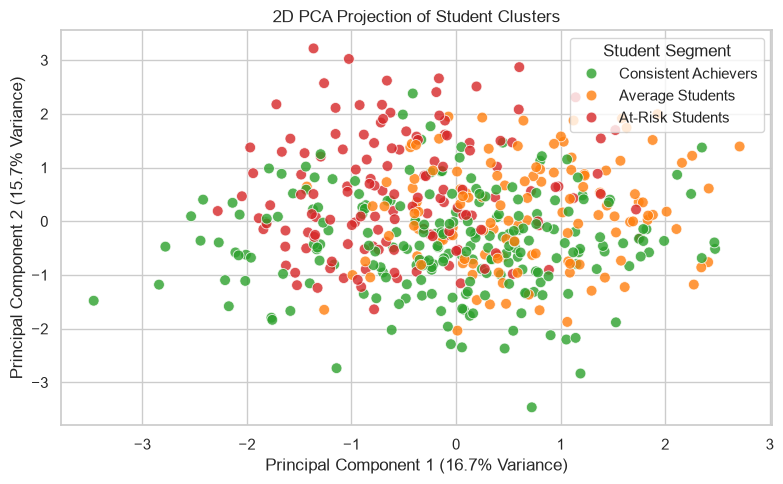

In [10]:
# Apply PCA with 2 components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_ratio = pca.explained_variance_ratio_
total_var = np.sum(var_ratio)

print(f'Principal Component 1 Explained Variance: {var_ratio[0]*100:.2f}%')
print(f'Principal Component 2 Explained Variance: {var_ratio[1]*100:.2f}%')
print(f'Total Variance Explained by 2 Components: {total_var*100:.2f}%')

# Add PCA components to DataFrame for plotting
df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

# Plot 2D PCA projection colored by cluster
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='PCA1',
    y='PCA2',
    hue='cluster_name',
    palette={'At-Risk Students': '#d62728', 'Average Students': '#ff7f0e', 'Consistent Achievers': '#2ca02c'},
    alpha=0.8,
    s=60
)
plt.title('2D PCA Projection of Student Clusters')
plt.xlabel(f'Principal Component 1 ({var_ratio[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({var_ratio[1]*100:.1f}% Variance)')
plt.legend(title='Student Segment', loc='upper right')
plt.tight_layout()
plt.savefig('../images/04_pca_clusters.png', dpi=150)
plt.show()

#### Summary of Clustering and PCA:
1. **Elbow and Silhouette analysis** confirmed that dividing students into **3 clusters** provides the clearest segmentation.
2. **Profiling** revealed three realistic student personas: *At-Risk Students*, *Average Students*, and *Consistent Achievers*.
3. **PCA reduction to 2 components** preserved significant variance and cleanly visualizes the separation between segments in 2D space.